# LZ78: analizar frases dadas y el coste de las referencias

**Tema 2 · Apartados 2.5 · Demostración orientativa: 10–20 minutos.**

Resolver un presupuesto a partir de una segmentación dada y estudiar cuándo compensa reutilizar frases.

## Cómo experimentar

Ejecuta todo de arriba abajo. Cambia un parámetro, predice qué ocurrirá y vuelve a ejecutar todas las celdas.
En Colab: *Entorno de ejecución → Ejecutar todas*. En Jupyter: *Kernel → Restart Kernel and Run All Cells*.
Los comentarios `#@param` permiten formularios en Colab; en Jupyter puedes editar los valores.

En la web, «Abrir en Colab» abre este cuaderno directamente en el navegador.
«Descargar cuaderno .ipynb» permite guardarlo y abrirlo en Jupyter o importarlo en Colab.
Puedes guardar una copia en tu Google Drive o descargar tu cuaderno desde Colab para conservar cambios.
Los cambios en tu sesión no modifican los originales de este repositorio.
La vista HTML muestra los resultados guardados; no recalcula las gráficas.
Los datos se generan en el propio cuaderno. No se instalan paquetes ni se descargan datos.
Solo se necesitan NumPy, Matplotlib y la biblioteca estándar de Python; IPython muestra las tablas.

## Modelo y pregunta

Partimos de tres **segmentaciones y pares ya dados**. El cuaderno no busca frases, no construye
el diccionario ni codifica o decodifica una entrada nueva. Permite inspeccionar una solución
y resolver su presupuesto de bits.

| Caso | Secuencia dada | Frases dadas |
|---|---|---|
| clase | `1010110100100` | 1 · 0 · 10 · 11 · 01 · 00 · 100 |
| periodica | `0101010101010101` | 0 · 1 · 01 · 010 · 10 · 101 · 0101 |
| mismos_recuentos | `0100110110001110` | 0 · 1 · 00 · 11 · 01 · 10 · 001 · 110 |

Las dos últimas secuencias tienen ocho ceros y ocho unos, pero distinta organización temporal.
Las tres terminan en frases nuevas completas; no hace falta añadir un convenio especial de sufijo final.

Usamos los índices y anchos de la teoría para K=2:
$$I_j=2i+s,\qquad w_j=\lceil\log_2(2j)\rceil.$$
Las palabras binarias de cada solución están dadas. El código cuenta sus longitudes y las compara
con un formato de referencias de ancho fijo, sin generar palabras binarias nuevas.

In [1]:
import math
import html
from fractions import Fraction
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, HTML
plt.rcParams.update({'font.size': 11, 'axes.spines.top': False,
                     'axes.spines.right': False})
AZUL = '#006d75'
NARANJA = '#b95028'
GRIS = '#617583'

def tabla(cabeceras, filas):
    def celda(x):
        return html.escape(str(x))
    cuerpo = ''.join('<tr>' + ''.join('<td>' + celda(x) + '</td>' for x in fila)
                     + '</tr>' for fila in filas)
    display(HTML('<div style="overflow-x:auto"><table><thead><tr>'
                 + ''.join('<th>' + celda(x) + '</th>' for x in cabeceras)
                 + '</tr></thead><tbody>' + cuerpo + '</tbody></table></div>'))

def entropia(prob):
    p = np.asarray(prob, dtype=float)
    p = p[p > 0]
    return float(-np.sum(p * np.log2(p)))

## Parámetros

Cambia un valor cada vez. Los rangos y las unidades aparecen en los comentarios.

In [2]:
#@title Parámetros
caso = "clase" #@param ["clase", "periodica", "mismos_recuentos"]
paso = 7 #@param {type:"integer"}
bits_indice_fijo = 8 #@param {type:"slider", min:6, max:12, step:1}
cabecera_bits = 32 #@param {type:"slider", min:0, max:256, step:8}
longitud_media_presupuesto = 8 #@param {type:"slider", min:5, max:32, step:1}
assert caso in ['clase', 'periodica', 'mismos_recuentos']
assert isinstance(paso, int) and 1 <= paso <= 8
assert isinstance(bits_indice_fijo, int) and 6 <= bits_indice_fijo <= 12
assert isinstance(cabecera_bits, int) and 0 <= cabecera_bits <= 256
assert isinstance(longitud_media_presupuesto, int) and 5 <= longitud_media_presupuesto <= 32
# Cada fila es un dato dado: frase, índice i, símbolo s, índice I, palabra C.
datos = {
    'clase': [('1',0,1,1,'1'), ('0',0,0,0,'00'), ('10',1,0,2,'010'),
              ('11',1,1,3,'011'), ('01',2,1,5,'0101'), ('00',2,0,4,'0100'), ('100',3,0,6,'0110')],
    'periodica': [('0',0,0,0,'0'), ('1',0,1,1,'01'), ('01',1,1,3,'011'),
                  ('010',3,0,6,'110'), ('10',2,0,4,'0100'), ('101',5,1,11,'1011'), ('0101',4,1,9,'1001')],
    'mismos_recuentos': [('0',0,0,0,'0'), ('1',0,1,1,'01'), ('00',1,0,2,'010'),
                        ('11',2,1,5,'101'), ('01',1,1,3,'0011'), ('10',2,0,4,'0100'),
                        ('001',3,1,7,'0111'), ('110',4,0,8,'1000')],
}
filas = datos[caso]
secuencia_dada = ''.join(f[0] for f in filas)
elegido = min(paso, len(filas))
anchos = np.array([len(f[4]) for f in filas])

## 1. Leer una solución sin construirla

La tabla contiene la solución completa. En el paso elegido se señalan la frase, el prefijo
al que apunta su índice y el símbolo añadido. Los datos anteriores permiten interpretar la referencia.
La figura ilustra esas posiciones en la entrada; no descubre automáticamente la segmentación.

j,Frase dada,"Par dado (i,s)",I_j dado,Palabra dada,Bits
1,1,"(0,1)",1,1,1
2,0,"(0,0)",0,00,2
3,10,"(1,0)",2,010,3
4,11,"(1,1)",3,011,3
5,01,"(2,1)",5,0101,4
6,00,"(2,0)",4,0100,4
7,100,"(3,0)",6,0110,4


Paso 7: frase 100; prefijo dado '10' (índice 3) y símbolo 0.
Índice dado I = 6; palabra dada 0110, de longitud 4 bits.
Entrada dada: 1010110100100


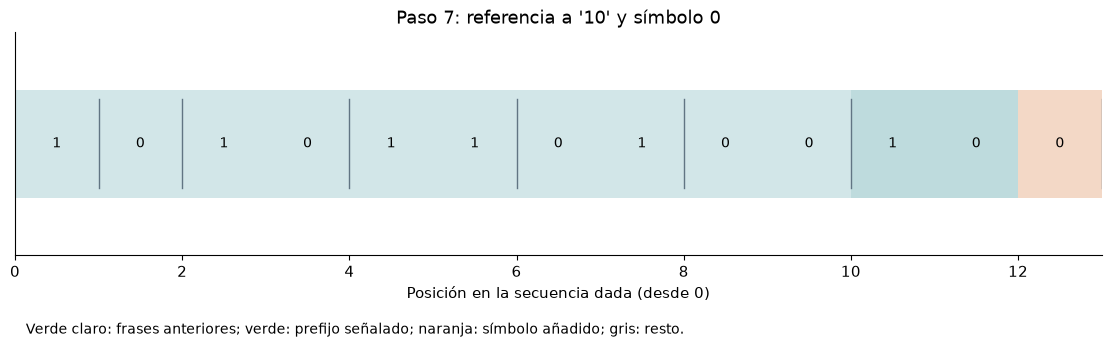

In [3]:
tabla(['j', 'Frase dada', 'Par dado (i,s)', 'I_j dado', 'Palabra dada', 'Bits'],
      [(j, f, f'({i},{s})', I, C, len(C)) for j, (f,i,s,I,C) in enumerate(filas,1)])
frase, indice, simbolo, I, C = filas[elegido-1]
prefijo = '' if indice == 0 else filas[indice-1][0]
print(f'Paso {elegido}: frase {frase}; prefijo dado {prefijo!r} (índice {indice}) y símbolo {simbolo}.')
print(f'Índice dado I = {I}; palabra dada {C}, de longitud {len(C)} bits.')
print('Entrada dada:', secuencia_dada)
inicio = sum(len(f[0]) for f in filas[:elegido-1])
fin = inicio+len(frase)
fig, ax = plt.subplots(figsize=(11, 3.3), layout='constrained')
for pos, s in enumerate(secuencia_dada):
    color = ('#d2e6e8' if pos < inicio else '#bedbdd' if pos < fin-1
             else '#f3d8c6' if pos < fin else '#eceff1')
    ax.barh([0], [1], left=pos, height=.58, color=color)
    ax.text(pos+.5, 0, s, ha='center', va='center', fontsize=10)
limites = np.cumsum([len(f[0]) for f in filas])
for limite in limites: ax.axvline(limite, ymin=.3, ymax=.7, c=GRIS, lw=1)
ax.set(xlim=(0,len(secuencia_dada)), ylim=(-.6,.6), xlabel='Posición en la secuencia dada (desde 0)',
       title=f'Paso {elegido}: referencia a {prefijo!r} y símbolo {simbolo}')
ax.set_yticks([])
ax.text(.01,-.35,'Verde claro: frases anteriores; verde: prefijo señalado; naranja: símbolo añadido; gris: resto.',
        transform=ax.transAxes,fontsize=10)
plt.show()

## 2. Resolver el tamaño de las soluciones dadas

Sumamos los anchos de las palabras dadas. La alternativa de ancho fijo asigna
$b$ bits al índice y uno al símbolo, es decir, $b+1$ bits por frase.
Aquí añadimos una cabecera configurable común a ambas representaciones comprimidas.
El diccionario dinámico no se transmite completo: se reproduce a partir de las referencias.
La cabecera representa otros metadatos hipotéticos, no una tabla que LZ78 tenga que enviar.

Comparar las dos secuencias de 16 bits permite comprobar que iguales frecuencias
no implican igual presupuesto de referencias. Con secuencias tan cortas, ninguna tiene por qué comprimirse.

Caso,Bits originales,Frases,H empírica,Carga dada,Carga + cabecera,Índice fijo + cabecera
clase,13,7,0.9957,21,53,95
periodica,16,7,1.0000,21,53,95
mismos_recuentos,16,8,1.0000,25,57,104


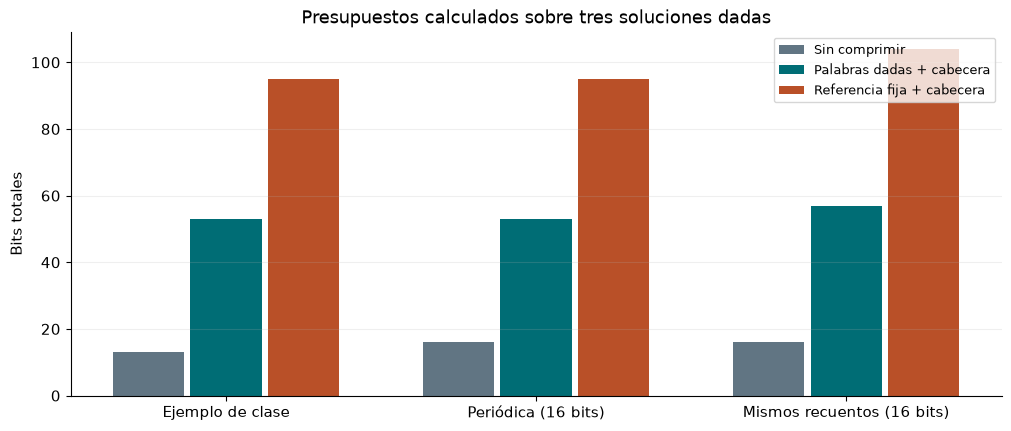

In [4]:
resumen = []
nombres = ['clase', 'periodica', 'mismos_recuentos']
cargas, fijas, originales = [], [], []
for nombre in nombres:
    fs = datos[nombre]
    n = sum(len(f[0]) for f in fs)
    carga = sum(len(f[4]) for f in fs)
    fijo = len(fs)*(bits_indice_fijo+1)
    original = ''.join(f[0] for f in fs)
    h = entropia([original.count('0')/n, original.count('1')/n])
    resumen.append((nombre,n,len(fs),f'{h:.4f}',carga,carga+cabecera_bits,fijo+cabecera_bits))
    originales.append(n); cargas.append(carga+cabecera_bits); fijas.append(fijo+cabecera_bits)
tabla(['Caso','Bits originales','Frases','H empírica','Carga dada','Carga + cabecera','Índice fijo + cabecera'],resumen)
fig, ax = plt.subplots(figsize=(10,4.2),layout='constrained')
xs = np.arange(3)
ax.bar(xs-.25,originales,width=.23,color=GRIS,label='Sin comprimir')
ax.bar(xs,cargas,width=.23,color=AZUL,label='Palabras dadas + cabecera')
ax.bar(xs+.25,fijas,width=.23,color=NARANJA,label='Referencia fija + cabecera')
ax.set_xticks(xs,['Ejemplo de clase','Periódica (16 bits)','Mismos recuentos (16 bits)'])
ax.set(ylabel='Bits totales',title='Presupuestos calculados sobre tres soluciones dadas')
ax.legend(fontsize=9);ax.grid(axis='y',alpha=.2);plt.show()

## 3. ¿Qué longitud media de frase haría rentable el presupuesto?

Supongamos que una segmentación de un bloque, obtenida fuera del cuaderno, contiene **M=64 frases nuevas**.
Sin conocer cuáles son, podemos sumar su coste de referencia:
$$B_{\mathrm{variable}}=\sum_{j=1}^{64}\lceil\log_2(2j)\rceil=385\text{ bits}.$$
Si su longitud media es $\ell$, el bloque original tiene $n=M\ell$ bits.
El ahorro requiere $M\ell>B_{\mathrm{variable}}+B_{\mathrm{cabecera}}$.

La curva es un **presupuesto condicionado a M y a la longitud media**. No demuestra que LZ78
produzca esas frases al procesar una secuencia concreta. Los controles cambian la hipótesis del problema,
no ejecutan el algoritmo. La alternativa fija también incluye un bit de símbolo por frase.

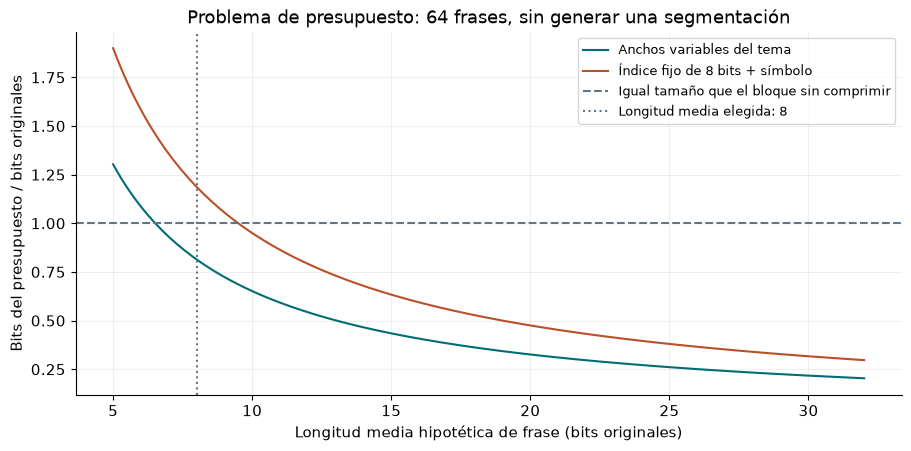

Hipótesis: 64 frases, media 8; bloque de 512 bits.
Variable: 417 bits; fijo: 608 bits.
Para ahorrar, media de frase > 6.5156 (variable) o > 9.5000 (fijo).


In [5]:
M_frases = 64
js = np.arange(1,M_frases+1)
coste_variable = int(np.ceil(np.log2(2*js)).sum())
coste_fijo = M_frases*(bits_indice_fijo+1)
medias_frase = np.linspace(5,32,200)
ratio_variable = (coste_variable+cabecera_bits)/(M_frases*medias_frase)
ratio_fijo = (coste_fijo+cabecera_bits)/(M_frases*medias_frase)
n_hipotetico = M_frases*longitud_media_presupuesto
fig,ax = plt.subplots(figsize=(9,4.4),layout='constrained')
ax.plot(medias_frase,ratio_variable,c=AZUL,label='Anchos variables del tema')
ax.plot(medias_frase,ratio_fijo,c=NARANJA,label=f'Índice fijo de {bits_indice_fijo} bits + símbolo')
ax.axhline(1,c=GRIS,ls='--',label='Igual tamaño que el bloque sin comprimir')
ax.axvline(longitud_media_presupuesto,c=GRIS,ls=':',label=f'Longitud media elegida: {longitud_media_presupuesto}')
ax.set(xlabel='Longitud media hipotética de frase (bits originales)',ylabel='Bits del presupuesto / bits originales',
       title='Problema de presupuesto: 64 frases, sin generar una segmentación')
ax.legend(fontsize=9);ax.grid(alpha=.2);plt.show()
print(f'Hipótesis: 64 frases, media {longitud_media_presupuesto}; bloque de {n_hipotetico} bits.')
print(f'Variable: {coste_variable+cabecera_bits} bits; fijo: {coste_fijo+cabecera_bits} bits.')
print(f'Para ahorrar, media de frase > {(coste_variable+cabecera_bits)/64:.4f} (variable) '
      +f'o > {(coste_fijo+cabecera_bits)/64:.4f} (fijo).')

## Antes de mirar la explicación

1. En el caso de clase, ¿a qué frase apunta la referencia del paso 7 y cuántos bits cuesta?
2. Pon la cabecera a cero. ¿La palabra del ejemplo de clase reduce el tamaño original?
3. Compara las dos soluciones de 16 bits. ¿Tienen la misma entropía empírica? ¿El mismo número de frases?
4. En el presupuesto de 64 frases, ¿cuál es el umbral de longitud media con una cabecera de 32 bits?
5. ¿Por qué aumentar el ancho fijo del índice reduce la ganancia aunque no cambien las frases?

## Explicación de lo observado

1. Apunta al índice 3 de `10` y añade 0 para describir `100`. El par dado es $(3,0)$,
   con $I_7=6$ y palabra `0110`, de cuatro bits.
2. No: las siete palabras dadas ocupan 21 bits, frente a 13 originales. Con cabecera se añade otro coste.
   Una representación correcta sin pérdidas puede aumentar el tamaño de un mensaje corto.
3. Ambas tienen ocho ceros y ocho unos, así que su entropía empírica sin memoria es un bit por símbolo.
   Las tablas dadas contienen siete y ocho frases; sus cargas ocupan 21 y 25 bits.
   La entropía de las frecuencias ignora el orden y no es una cota para una fuente temporal determinista.
4. La carga variable es 385 bits y el total 417. Por tanto, se necesita
   $\ell>417/64=6.515625$. Con media 8, el bloque original tiene 512 bits y el presupuesto ahorra
   aproximadamente 18.55 %. El índice fijo de 8 bits más símbolo cuesta 608 bits con la cabecera,
   por lo que con esa misma hipótesis aumenta el tamaño.
5. Cada referencia cuesta más. El ahorro depende de que la longitud de la frase sustituida
   compense los bits del índice, el símbolo y la cabecera amortizada.

## Comprobación del modelo

Comprobamos datos dados y sumas del presupuesto, sin implementar el algoritmo.

In [6]:
for nombre, fs in datos.items():
    for j,(frase,i,s,I,C) in enumerate(fs,1):
        assert 0 <= i < j and s in [0,1]
        assert I == 2*i+s and int(C,2) == I
        assert len(C) == math.ceil(math.log2(2*j))
assert sum(len(f[4]) for f in datos['clase']) == 21
periodica = ''.join(f[0] for f in datos['periodica'])
otra = ''.join(f[0] for f in datos['mismos_recuentos'])
assert periodica == '01'*8 and len(otra) == 16
assert periodica.count('0') == otra.count('0') == 8
assert coste_variable == 385
assert np.isclose((385+32)/(64*8),417/512)
print('Índices dados, anchos y costes totales comprobados; no se segmentan ni codifican entradas nuevas.')

Índices dados, anchos y costes totales comprobados; no se segmentan ni codifican entradas nuevas.


## Referencias

Ejemplo y código propios para TDI.

- TDI, tema 2, apartados 2.5: «LZ78: representación de cada frase, conversión de índices y eficiencia».

Los supuestos y las convenciones de este experimento se explican en «Modelo y pregunta».